# Chapter 9 — Modeling Probabilities and Nonlinearities: Activation Functions
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

Until now a layer was `matrix product → (ReLU)` and the output was a raw number compared with a target by squared error. This chapter fills in the missing pieces:

1. what an **activation function** is, what makes a *good* one, and the standard choices (ReLU, sigmoid, tanh),
2. the **softmax** output layer, which turns raw scores into a **probability distribution** over classes,
3. the **cross-entropy** loss that pairs naturally with softmax, and why the pair gives such a clean gradient,
4. a **vanishing-gradient** experiment showing why the choice of hidden activation matters.

> Data: the 8×8 scikit-learn digits (scaled to 0–1), 1200 training and 597 test images. Code and experiments are my own; the concepts follow the chapter.

**Roadmap**
1. Activation functions and their derivatives
2. Softmax
3. Cross-entropy and the gradient $\hat{\mathbf p}-\mathbf y$
4. Training a digit classifier: MSE vs softmax + cross-entropy
5. Comparing hidden activations; vanishing gradients

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target
order = np.random.default_rng(0).permutation(len(X_all))
Xtr, ytr = X_all[order[:1200]], y_all[order[:1200]]
Xte, yte = X_all[order[1200:]], y_all[order[1200:]]
Ytr = np.eye(10)[ytr]
print(Xtr.shape, Xte.shape)

(1200, 64) (597, 64)


## 1. Activation functions

An **activation function** $f$ is applied element-wise to a layer's weighted sum: $\mathbf l_1 = f(\mathbf l_0W_{01})$.
Without it, stacked layers collapse to one linear map (Chapter 3). The chapter lists what a *useful* activation must satisfy:

1. **Continuous and infinitely many outputs** (no jumps in the input→output relation), so small input changes give small output changes and gradients exist.
2. **Monotonic** (never goes down as the input goes up), so a bigger input never *reduces* a unit's vote — otherwise the same weight would mean opposite things in different ranges.
3. **Nonlinear**, so a unit can switch on or off ("selective correlation") — this is what lets a deep network model non-linear patterns.
4. **Efficiently computable**, because it is evaluated billions of times.

| Function | Formula | Output range | Derivative |
|---|---|---|---|
| ReLU | $\max(0,z)$ | $[0,\infty)$ | $1$ if $z>0$, else $0$ |
| Sigmoid | $\sigma(z)=\dfrac1{1+e^{-z}}$ | $(0,1)$ | $\sigma(z)\,(1-\sigma(z))$ |
| tanh | $\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $(-1,1)$ | $1-\tanh^2 z$ |

Sigmoid is the "probability of a yes" for a *single* output; tanh is a zero-centred relative of it; ReLU is the cheapest and today's default for hidden layers.
Backpropagation needs the **derivative**, so each activation comes with one. We verify the derivatives numerically.

relu     derivative matches numeric: True
sigmoid  derivative matches numeric: True
tanh     derivative matches numeric: True


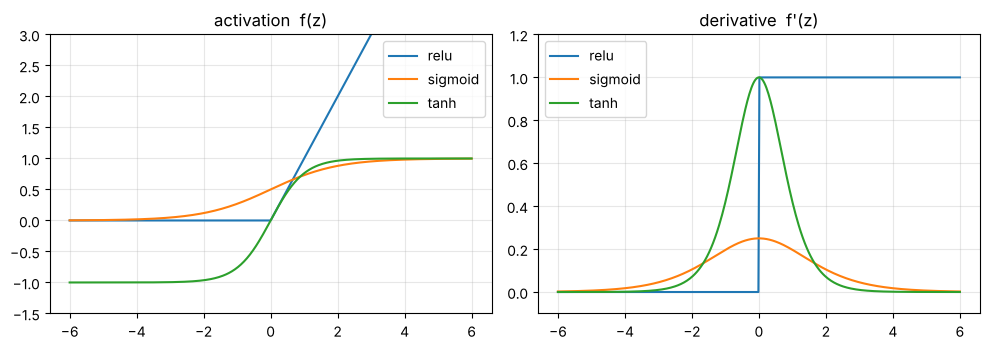

max derivative: sigmoid 0.25, tanh 1.00, relu 1.00


In [2]:
relu    = lambda z: np.maximum(0, z)
d_relu  = lambda z: (z > 0).astype(float)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
d_sigmoid = lambda z: sigmoid(z) * (1 - sigmoid(z))
tanh    = np.tanh
d_tanh  = lambda z: 1 - np.tanh(z) ** 2

acts = {'relu': (relu, d_relu), 'sigmoid': (sigmoid, d_sigmoid), 'tanh': (tanh, d_tanh)}

z = np.linspace(-6, 6, 400)
h = 1e-6
zc = np.array([-2.5, -0.7, 0.3, 1.9])        # avoid z = 0, where ReLU has a kink
for name, (f, df) in acts.items():
    numeric = (f(zc + h) - f(zc - h)) / (2 * h)
    print(f"{name:8s} derivative matches numeric: {np.allclose(df(zc), numeric, atol=1e-6)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name, (f, df) in acts.items():
    axes[0].plot(z, f(z), label=name)
    axes[1].plot(z, df(z), label=name)
axes[0].set_ylim(-1.5, 3); axes[0].set_title('activation  f(z)');  axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_ylim(-0.1, 1.2); axes[1].set_title("derivative  f'(z)"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/activations.png', dpi=110); plt.show()
print(f"max derivative: sigmoid {d_sigmoid(z).max():.2f}, tanh {d_tanh(z).max():.2f}, relu {d_relu(z).max():.2f}")

**Reading the output.** All three derivative formulas agree with numerical differentiation. Notice the right-hand plot: the sigmoid's slope never exceeds 0.25 and it is
almost zero for $|z|>4$; tanh's slope peaks at 1 but also vanishes for large $|z|$ ("saturation"); ReLU's slope is exactly 1 for every positive input. This difference is the subject of Section 5.

## 2. Softmax

For a classification problem with $K$ classes the network produces $K$ raw scores (**logits**) $z_1,\dots,z_K$. We want them turned into **probabilities**:
non-negative and summing to 1. The **softmax** does exactly that:

$$\operatorname{softmax}(\mathbf z)_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}.$$

- The exponential makes every value positive and **exaggerates differences** (the largest score gets most of the probability).
- Dividing by the sum makes the outputs add to 1.
- It is **shift-invariant**: adding the same constant $c$ to all logits changes nothing, since $e^{c}$ cancels. We use this for **numerical stability** by subtracting $\max_k z_k$ first (otherwise $e^{1000}$ overflows).

In [3]:
def softmax(Z):
    Z = Z - Z.max(axis=-1, keepdims=True)         # stability trick; the result is unchanged
    E = np.exp(Z)
    return E / E.sum(axis=-1, keepdims=True)

logits = np.array([2.0, 1.0, 0.1])
p = softmax(logits)
print("logits           :", logits)
print("probabilities    :", p, " sum =", p.sum())
print("shift by +100    :", softmax(logits + 100))
with np.errstate(all="ignore"):
    print("naive formula on shifted logits:", np.exp(logits + 1000) / np.exp(logits + 1000).sum(), "  (overflow -> nan)")

# softmax sharpens: scaling the logits makes the choice more confident
for s in [0.5, 1, 3]:
    print(f"scale logits x{s:<3}:", softmax(logits * s))

logits           : [2.  1.  0.1]
probabilities    : [0.659  0.2424 0.0986]  sum = 1.0
shift by +100    : [0.659  0.2424 0.0986]
naive formula on shifted logits: [nan nan nan]   (overflow -> nan)
scale logits x0.5: [0.5017 0.3043 0.194 ]
scale logits x1  : [0.659  0.2424 0.0986]
scale logits x3  : [0.9495 0.0473 0.0032]


**Reading the output.** The probabilities sum to 1, shifting the logits by 100 changes nothing, and the naive formula really does break (`nan`) where the stabilized one does not.
Scaling the logits up makes the distribution more peaked: the network's confidence is controlled by the *size* of its raw scores.

## 3. Cross-entropy and the gradient $\hat{\mathbf p}-\mathbf y$

Given the predicted distribution $\hat{\mathbf p}$ and the one-hot true label $\mathbf y$ (all zeros except a 1 at the true class $c$), the **cross-entropy loss** is

$$L=-\sum_k y_k\log \hat p_k=-\log \hat p_c .$$

It is simply **minus the log of the probability the network gave to the correct class**: 0 when it is certain and right, and growing without bound as the probability of the right answer goes to 0.
That is a much harsher punishment for confident mistakes than squared error, whose penalty is capped at 1 per output.

**The beautiful gradient.** With $\hat p_k = e^{z_k}/\sum_j e^{z_j}$:

$$\frac{\partial L}{\partial z_k}=\hat p_k-y_k .$$

*Derivation.* $L=-z_c+\log\sum_j e^{z_j}$. Differentiating, $\partial L/\partial z_k=-\mathbb 1[k=c]+e^{z_k}/\sum_j e^{z_j}=\hat p_k-y_k$. ∎

So the output "delta" is again just **prediction − target**, exactly as with squared error and a linear output in Chapter 5/6, and the rest of backpropagation is unchanged. The gradient does **not** shrink when the network is
confidently wrong, which is why this pair trains well. We check the formula numerically.

analytic  p - y : [[ 0.7333  0.0074 -0.8553  0.054   0.0606]]
numerical       : [[ 0.7333  0.0074 -0.8553  0.054   0.0606]]
match: True


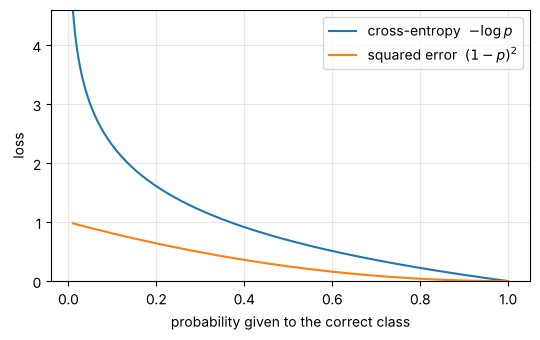

In [4]:
def cross_entropy(P, Y):
    return -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))

rng = np.random.default_rng(3)
Z = rng.normal(size=(1, 5)); Y = np.eye(5)[[2]]

analytic = softmax(Z) - Y
numeric = np.zeros_like(Z)
h = 1e-6
for k in range(Z.shape[1]):
    Zp, Zm = Z.copy(), Z.copy(); Zp[0, k] += h; Zm[0, k] -= h
    numeric[0, k] = (cross_entropy(softmax(Zp), Y) - cross_entropy(softmax(Zm), Y)) / (2 * h)
print("analytic  p - y :", analytic)
print("numerical       :", numeric)
print("match:", np.allclose(analytic, numeric, atol=1e-6))

# Loss as a function of the probability given to the correct class
p_right = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(p_right, -np.log(p_right), label='cross-entropy  $-\\log p$')
ax.plot(p_right, (1 - p_right) ** 2, label='squared error  $(1-p)^2$')
ax.set_xlabel('probability given to the correct class'); ax.set_ylabel('loss'); ax.set_ylim(0, 4.6); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/loss_comparison.png', dpi=110); plt.show()

**Reading the output.** The formula $\hat{\mathbf p}-\mathbf y$ equals the numerical gradient. The plot shows why cross-entropy is preferred for classification: as the probability of the correct class approaches 0, the cross-entropy loss
(and its pressure to change) grows without limit, while squared error flattens out at 1.

## 4. Training a digit classifier: squared error vs softmax + cross-entropy

Same network (64 → 64 hidden ReLU → 10), same initialization, same learning rate and epochs. Only the output layer and loss differ:

| | output | loss | output delta |
|---|---|---|---|
| A | linear scores $\hat{\mathbf y}$ | squared error | $\hat{\mathbf y}-\mathbf y$ |
| B | softmax $\hat{\mathbf p}$ | cross-entropy | $\hat{\mathbf p}-\mathbf y$ |

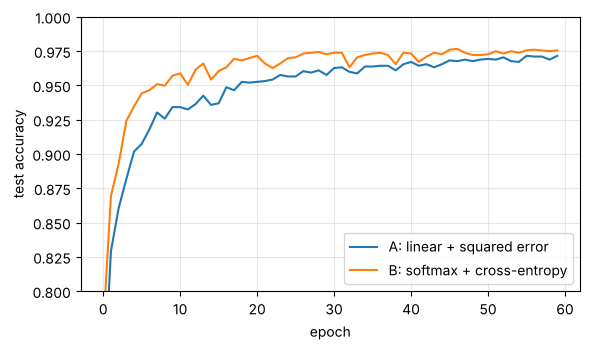

setting                         | train acc | test acc (mean of 3 seeds)
A: linear + squared error       |     0.984 | 0.972  (+/- 0.003)
B: softmax + cross-entropy      |     0.995 | 0.975  (+/- 0.002)
test accuracy after 5 epochs   : A 0.902  B 0.935


In [5]:
def train(hidden_act='relu', loss='ce', H=64, lr=0.1, epochs=60, batch=32, seed=0, n_layers=1, init_std=None, track_grad=False):
    f, df = acts[hidden_act]
    rng = np.random.default_rng(seed)
    sizes = [64] + [H] * n_layers + [10]
    Ws = [rng.normal(0, init_std if init_std else np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
    hist = {'train_loss': [], 'test_acc': [], 'train_acc': [], 'grad_first': [], 'grad_last': []}

    def forward(X):
        zs, ls = [], [X]
        for i, W in enumerate(Ws):
            z = ls[-1] @ W
            zs.append(z)
            ls.append(f(z) if i < len(Ws) - 1 else z)
        return zs, ls

    for ep in range(epochs):
        idx = rng.permutation(len(Xtr))
        g_first = g_last = 0.0
        for s in range(0, len(idx), batch):
            b = idx[s:s + batch]
            zs, ls = forward(Xtr[b])
            out = softmax(ls[-1]) if loss == 'ce' else ls[-1]
            delta = (out - Ytr[b])
            grads = [None] * len(Ws)
            for i in range(len(Ws) - 1, -1, -1):
                grads[i] = ls[i].T @ delta / len(b)
                if i > 0:
                    delta = (delta @ Ws[i].T) * df(zs[i - 1])
            for W, g in zip(Ws, grads):
                W -= lr * g
            g_first += np.linalg.norm(grads[0]); g_last += np.linalg.norm(grads[-1])
        zs, ls = forward(Xtr); out = softmax(ls[-1]) if loss == 'ce' else ls[-1]
        hist['train_loss'].append(cross_entropy(softmax(ls[-1]), Ytr) if loss == 'ce' else np.mean(np.sum((out - Ytr) ** 2, 1)))
        hist['train_acc'].append(np.mean(ls[-1].argmax(1) == ytr))
        hist['test_acc'].append(np.mean(forward(Xte)[1][-1].argmax(1) == yte))
        n_b = int(np.ceil(len(idx) / batch)); hist['grad_first'].append(g_first / n_b); hist['grad_last'].append(g_last / n_b)
    return hist

resA = [train(loss='mse', seed=s) for s in range(3)]
resB = [train(loss='ce', seed=s) for s in range(3)]
m = lambda rs, k: np.mean([r[k] for r in rs], axis=0)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(m(resA, 'test_acc'), label='A: linear + squared error'); ax.plot(m(resB, 'test_acc'), label='B: softmax + cross-entropy')
ax.set_xlabel('epoch'); ax.set_ylabel('test accuracy'); ax.set_ylim(0.8, 1.0); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/mse_vs_ce.png', dpi=110); plt.show()

print("setting                         | train acc | test acc (mean of 3 seeds)")
for name, rs in [('A: linear + squared error', resA), ('B: softmax + cross-entropy', resB)]:
    print(f"{name:31s} | {m(rs,'train_acc')[-1]:9.3f} | {m(rs,'test_acc')[-1]:.3f}  (+/- {np.std([r['test_acc'][-1] for r in rs]):.3f})")
print("test accuracy after 5 epochs   : A", round(m(resA,'test_acc')[4], 3), " B", round(m(resB,'test_acc')[4], 3))

test accuracy 0.975;  mean confidence when right 0.968, when wrong 0.627


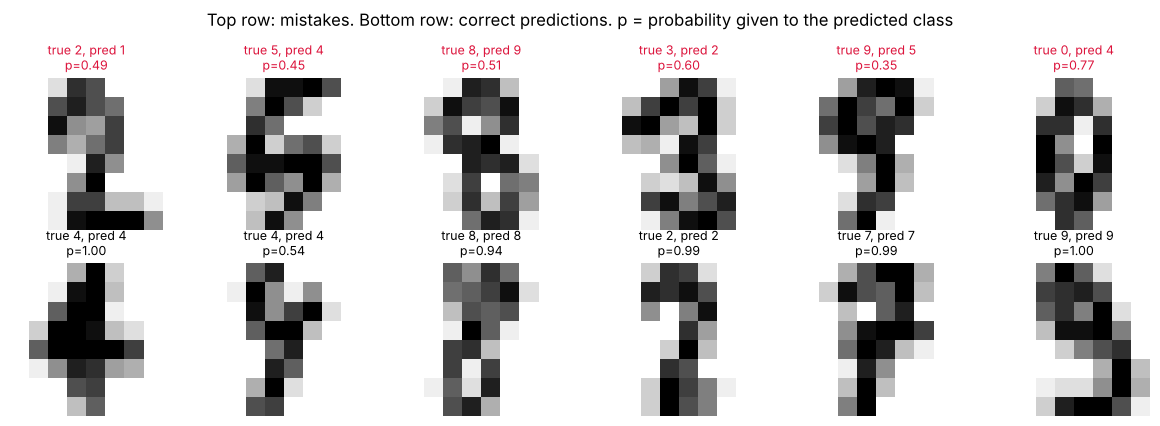

In [6]:
# What the softmax network "believes": predicted probabilities for a few test images (trained network B, retrained to keep the weights)
f, df = acts['relu']
rng = np.random.default_rng(0)
W1 = rng.normal(0, np.sqrt(2 / 64), (64, 64)); W2 = rng.normal(0, np.sqrt(2 / 64), (64, 10))
for ep in range(60):
    idx = rng.permutation(len(Xtr))
    for s in range(0, len(idx), 32):
        b = idx[s:s + 32]; z1 = Xtr[b] @ W1; l1 = relu(z1)
        d2 = softmax(l1 @ W2) - Ytr[b]; d1 = (d2 @ W2.T) * (z1 > 0)
        W2 -= 0.1 * l1.T @ d2 / len(b); W1 -= 0.1 * Xtr[b].T @ d1 / len(b)
P = softmax(relu(Xte @ W1) @ W2)
conf = P.max(1); pred = P.argmax(1); wrong = np.where(pred != yte)[0]
print(f"test accuracy {np.mean(pred == yte):.3f};  mean confidence when right {conf[pred == yte].mean():.3f}, when wrong {conf[wrong].mean():.3f}")

fig, axes = plt.subplots(2, 6, figsize=(12, 4.3))
show = list(wrong[:6]) + list(np.where(pred == yte)[0][:6])
for ax, i in zip(axes.ravel(), show):
    ax.imshow(Xte[i].reshape(8, 8), cmap='gray_r'); ax.axis('off')
    ax.set_title(f"true {yte[i]}, pred {pred[i]}\np={conf[i]:.2f}", fontsize=9, color='crimson' if pred[i] != yte[i] else 'black')
plt.suptitle('Top row: mistakes. Bottom row: correct predictions. p = probability given to the predicted class')
plt.tight_layout(); plt.savefig('outputs/predicted_probabilities.png', dpi=110); plt.show()

**Reading the output.** Both losses learn the task well (about 97% test accuracy), but softmax + cross-entropy is ahead: 0.975 vs 0.972 at the end (a small gap, close to the seed spread) and clearly faster early on
(0.935 vs 0.902 after 5 epochs). The softmax network additionally gives a *probability*. Its mean confidence is about 0.97 on correct predictions but only about 0.63 on its mistakes, a useful signal
(the model can say "I am not sure"), which a raw score does not provide as directly.

## 5. Which hidden activation? Vanishing gradients

Backpropagation multiplies the error signal by $f'(z)$ at every layer on the way back. If $f'$ is small, the signal shrinks layer after layer — the **vanishing-gradient problem**.
Sigmoid's slope is at most 0.25, so through $n$ sigmoid layers the signal is scaled by at most $0.25^n$ (before the effect of the weights). ReLU's slope is 1 for active units.

Experiment: a **5-hidden-layer** network (64 units each) with each activation, same small-weight initialization ($\sigma=0.1$) so the comparison is fair. We record the size (norm) of the weight gradient in the
**first** layer vs the **last** layer, averaged over the first epoch, and the resulting accuracy.

activation | grad norm first layer (epoch 1) | grad norm last layer (epoch 1) | ratio first/last | test acc
sigmoid    |                         0.00021 |                        0.71671 |           0.0003 | 0.089
tanh       |                         0.28703 |                        0.24216 |           1.1853 | 0.988
relu       |                         0.04260 |                        0.03809 |           1.1186 | 0.968


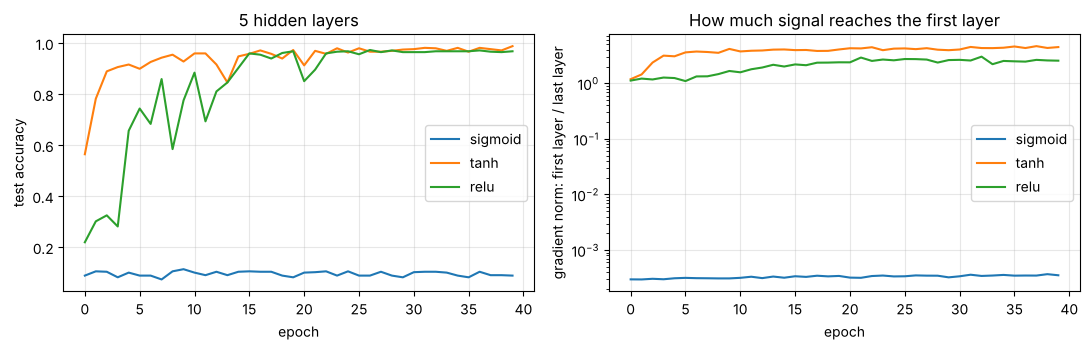

In [7]:
results = {}
for name in ['sigmoid', 'tanh', 'relu']:
    results[name] = train(hidden_act=name, loss='ce', n_layers=5, init_std=0.1, epochs=40, lr=0.1, seed=0)

print("activation | grad norm first layer (epoch 1) | grad norm last layer (epoch 1) | ratio first/last | test acc")
for name, r in results.items():
    g1, g2 = r['grad_first'][0], r['grad_last'][0]
    print(f"{name:10s} | {g1:31.5f} | {g2:30.5f} | {g1 / g2:16.4f} | {r['test_acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, r in results.items():
    axes[0].plot(r['test_acc'], label=name)
    axes[1].semilogy(np.array(r['grad_first']) / np.array(r['grad_last']), label=name)
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('test accuracy'); axes[0].set_title('5 hidden layers'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('gradient norm: first layer / last layer'); axes[1].set_title('How much signal reaches the first layer'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/vanishing_gradients.png', dpi=110); plt.show()

**Reading the output.** The sigmoid network is the clear failure: only about 0.0003 of the last layer's gradient size reaches the first layer, and after 40 epochs its test accuracy is about 0.09, i.e. chance level
for 10 classes. The signal vanished on the way back (each sigmoid layer multiplies it by at most 0.25), so the network barely learned. tanh and ReLU keep a first/last ratio of about 1 and train well.
In this particular run **tanh** (0.988) is slightly *ahead* of ReLU (0.968), so the lesson is not "ReLU always wins"; it is that **saturating, small-slope activations (sigmoid) are dangerous in deep stacks**, while tanh and ReLU
are fine. Caveats: one dataset, one depth, one seed and one small-weight initialization. Smarter initialization (He/Xavier scaling, the default in the training function above) reduces the problem. ReLU's practical
advantages (cheap, no saturation for positive inputs, works in very deep networks) show up more at larger scale than in this toy.

## Summary

| Idea | What it is | Key formula |
|---|---|---|
| Activation function | non-linearity applied element-wise to each layer | must be continuous, monotonic, nonlinear, cheap |
| ReLU / sigmoid / tanh | the standard choices | $\max(0,z)$; $1/(1+e^{-z})$; $\tanh z$ |
| Derivative | needed by backprop | $\delta_{l}=(\delta_{l+1}W^{\top})\odot f'(z_l)$ |
| Softmax | scores → probabilities | $e^{z_k}/\sum_j e^{z_j}$ (subtract the max for stability) |
| Cross-entropy | $-\log$ of the probability of the right class | $\partial L/\partial z=\hat p-y$ |
| Vanishing gradients | small $f'$ shrinks the learning signal layer by layer | sigmoid slope $\le 0.25$ |

**Key takeaway:** hidden layers want a non-saturating, cheap nonlinearity (ReLU is the standard; sigmoid is a poor choice for deep hidden stacks); a classification output wants softmax with cross-entropy, whose gradient is simply *prediction − target*.